<h1 align=center style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
شکارچی قارچ
</font>
</h1>

<center>
<img src="mushroom.jpg">
</center>

<h2 align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
مقدمه و صورت مسئله
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
    قارچ‌ها چندان اهل شوخی نیستند و اگر یکی از گونه‌های سمی آن را با نوع خوراکی اشتباه بگیرید خطر مرگ خواهد داشت! همان‌طور که هر چند وقت یکبار خبری از این دست را در کشور خودمان نیز می‌شنویم. به همین علت است که اصلاً توصیه نمی‌شود وقتی در دل طبیعت به قارچی برخوردید هوس خوردن آن را کنید. زیرا حتی اگر از قبل با برخی از گونه‌های سمی و خوراکی آشنا باشید هم آنقدر جزئیات زیاد است که تنها یک متخصص یا قارچ‌شناس قادر است با درجه‌ی اطمینان بالایی به تفکیک این گونه‌ها بپردازد. در این تمرین از یک مجموعه‌داده‌ی قارچی کمک خواهیم گرفت و الگوریتم جنگل تصادفی را روی آن اجرا می‌کنیم تا به مدلی دست یابیم که قادر باشد با دریافت چندین ویژگی از یک قارچ،‌ سمی یا خوراکی بودن آن را نتیجه‌گیری و اعلام کند. جالب است بدانید یک اصطلاح قدیمی برای عمل رفتن به طبیعت و جمع‌آوری قارچ‌ها (اکثراً با هدف خوراکی) وجود دارد که به آن <i>شکار قارچ (mushroom hunting)</i> می‌گویند. لازمه‌‌ی اینکه شخصی شکارچی قارچ شود این است که با گونه‌های مختلف آن آشنا باشد و بتواند به کمک دانش و تجربه‌ی خود براساس ویژگی‌های مختلف،‌ نوع قارچ را تشخیص دهد. اما مشاهده خواهید کرد تا انتهای این تمرین به مدلی دست خواهیم یافت که به‌صورت هوشمند و با دقت بیشتری از انسان قادر به انجام همین کار خواهد بود.
</font>
</p>

<h2 align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
وارد کردن کتابخانه‌های مورد نیاز
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
    ابتدا کتابخانه‌های مورد نیازتان را وارد کنید.
</font>
</p>

In [1]:
import numpy as np
import pandas as pd

<h2 align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
معرفی مجموعه‌داده
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
مجموعه‌داده‌ای که در این تمرین استفاده خواهیم کرد شامل نمونه‌هایی فرضی از ۲۳ گونه‌ی مختلف قارچ‌های تیغک‌دار است. هرکدام از این گونه‌ها به عنوان قطعاً خوراکی،‌ قطعاً سمی، عدم تشخیص خوراکی‌بودن و توصیه‌نشده شناخته شده‌اند. مواردی که قطعیتی برای آن وجود ندارد نیز در نهایت برچسب سمی خورده‌اند تا فقط دو کلاس خوراکی و سمی داشته باشیم. ویژگی‌هایی که برای هر قارچ استخراج و در نظر گرفته شده در جدول زیر آمده است. مقدار هر ویژگی بصورت مخفف در مجموعه‌داده ذخیره شده اما کلمات اصلی نظیر هر مخفف نیز در جدول قابل مطالعه است. توجه داشته باشید که در ستون <code>class</code> که همان ستون متغیر هدف ما است مقدار <code>e</code> به معنی خوراکی بودن و مقدار <code>p</code> به معنی سمی بودن است.
</font>
</p>

<center>
<img src="structure.jpg">
</center>

<center>
<div dir=rtl style="direction: rtl;line-height:200%;font-family:vazir;font-size:medium">
<font face="vazir" size=3>
    
|ستون|توضیحات|مقادیر و مخفف‌ها|
|:------:|:---:|:------:|
|cap-shape|شکل کلاهک| bell=b, conical=c, convex=x, flat=f, knobbed=k, sunken=s |
|cap-surface|سطح کلاهک| fibrous=f, grooves=g, scaly=y, smooth=s |
|cap-color|رنگ کلاهک| brown=n, buff=b, cinnamon=c, gray=g, green=r, pink=p, purple=u, red=e, white=w, yellow=y |
|bruises|کبودی| bruises=t, no=f |
|odor|عطر| almond=a, anise=l, creosote=c, fishy=y, foul=f, musty=m, none=n, pungent=p, spicy=s |
|gill-attachment|چسبندگی تیغه| attached=a, descending=d, free=f, notched=n |
|gill-spacing|فاصله تیغه| close=c, crowded=w, distant=d |
|gill-size|اندازه تیغه| broad=b, narrow=n |
|gill-color|رنگ تیغه| black=k, brown=n, buff=b, chocolate=h, gray=g, green=r, orange=o, pink=p, purple=u, red=e, white=w, yellow=y |
|stalk-shape|شکل ساقه| enlarging=e, tapering=t |
|stalk-root|ریشه ساقه| bulbous=b, club=c, cup=u, equal=e, rhizomorphs=z, rooted=r, missing=? |
|stalk-surface-above-ring|سطح ریشه بالای حلقه| fibrous=f, scaly=y, silky=k, smooth=s |
|stalk-surface-below-ring|سطح ریشه زیر حلقه| fibrous=f, scaly=y, silky=k, smooth=s |
|stalk-color-above-ring|رنگ ریشه بالای حلقه| brown=n, buff=b, cinnamon=c, gray=g, orange=o, pink=p, red=e, white=w, yellow=y |
|stalk-color-below-ring|رنگ ریشه زیر حلقه| brown=n, buff=b, cinnamon=c, gray=g, orange=o, pink=p, red=e, white=w, yellow=y |
|veil-type|نوع غشا| partial=p, universal=u |
|veil-color|رنگ غشا| brown=n, orange=o, white=w, yellow=y |
|ring-number|تعداد حلقه| none=n, one=o, two=t |
|ring-type|نوع حلقه| cobwebby=c, evanescent=e, flaring=f, large=l, none=n, pendant=p, sheathing=s, zone=z |
|spore-print-color|رنگ نقش هاگ| black=k, brown=n, buff=b, chocolate=h, green=r, orange=o, purple=u, white=w, yellow=y |
|population|جمعیت| abundant=a, clustered=c, numerous=n, scattered=s, several=v, solitary=y |
|habitat|زیست‌گاه| grasses=g, leaves=l, meadows=m, paths=p, urban=u, waste=w, woods=d |
|class|گونه (برچسب)| edible=e, poisonous=p |
    
</font>
</div>
</center>


<h2 align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
خواندن مجموعه‌داده
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
    در ابتدا نیاز است فایل‌های مجموعه‌داده را بخوانید. نمونه‌های آموزشی در فایل <code>train.csv</code> و نمونه‌های آزمون که باید دسته‌ی آن‌ها را پیش‌بینی کنید در فایل <code>test.csv</code> ذخیره شده‌اند. اگر لازم دانستید می‌توانید به دلخواه خود بخشی از مجموعه‌ی آموزشی را به عنوان مجموعه‌ی اعتبارسنجی نیز جدا کنید.
</font>
</p>

In [3]:
train_data = pd.read_csv('data/train.csv')
train_data

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,e,b,y,w,t,a,f,c,b,w,...,s,w,w,p,w,o,p,k,s,m
1,p,x,y,n,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
2,e,f,s,y,t,a,f,w,n,w,...,s,w,w,p,w,o,p,n,v,d
3,p,x,f,g,f,f,f,c,b,h,...,k,p,p,p,w,o,l,h,v,g
4,e,x,f,n,f,n,f,w,b,k,...,s,w,w,p,w,o,e,k,s,g
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6494,p,x,y,g,f,f,f,c,b,p,...,k,p,b,p,w,o,l,h,v,d
6495,p,f,y,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,g
6496,e,x,s,w,f,n,f,w,b,n,...,f,w,w,p,w,o,e,n,a,g
6497,e,x,f,e,t,n,f,c,b,w,...,s,p,p,p,w,o,p,n,v,d


In [5]:
test_data = pd.read_csv('data/test.csv')
test_data

,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,x,f,n,t,n,f,c,b,p,t,...,s,g,p,p,w,o,p,k,y,d
1,x,f,w,f,n,f,w,b,n,t,...,f,w,w,p,w,o,e,k,a,g
2,x,f,g,f,n,f,w,b,n,t,...,s,w,w,p,w,o,e,k,a,g
3,f,f,g,t,n,f,c,b,u,t,...,s,g,w,p,w,o,p,n,y,d
4,x,y,e,t,n,f,c,b,n,t,...,s,p,p,p,w,o,p,n,v,d
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1620,k,y,n,f,f,f,c,n,b,t,...,k,w,p,p,w,o,e,w,v,d
1621,f,y,n,f,y,f,c,n,b,t,...,s,p,w,p,w,o,e,w,v,p
1622,x,y,g,f,f,f,c,b,p,e,...,k,b,n,p,w,o,l,h,v,p
1623,x,s,w,t,f,f,c,b,p,t,...,s,w,w,p,w,o,p,h,s,u


In [6]:
train_data.describe()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
count,6499,6499,6499,6499,6499,6499,6499,6499,6499,6499,...,6499,6499,6499,6499,6499,6499,6499,6499,6499,6499
unique,2,6,4,10,2,9,2,2,2,12,...,4,9,9,1,4,3,5,9,6,7
top,e,x,y,n,f,n,f,c,b,b,...,s,w,w,p,w,o,p,w,v,d
freq,3387,2954,2588,1821,3774,2829,6329,5448,4498,1372,...,3969,3587,3507,6499,6337,5981,3210,1899,3225,2519


In [7]:
test_data.describe()

,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
count,1625,1625,1625,1625,1625,1625,1625,1625,1625,1625,...,1625,1625,1625,1625,1625,1625,1625,1625,1625,1625
unique,6,3,10,2,9,2,2,2,12,2,...,4,9,9,1,4,3,5,9,6,7
top,x,y,n,f,n,f,c,b,b,t,...,s,w,w,p,w,o,p,w,v,d
freq,702,656,463,974,699,1585,1364,1114,356,937,...,967,877,877,1625,1587,1507,758,489,815,629


In [8]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6499 entries, 0 to 6498
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     6499 non-null   object
 1   cap-shape                 6499 non-null   object
 2   cap-surface               6499 non-null   object
 3   cap-color                 6499 non-null   object
 4   bruises                   6499 non-null   object
 5   odor                      6499 non-null   object
 6   gill-attachment           6499 non-null   object
 7   gill-spacing              6499 non-null   object
 8   gill-size                 6499 non-null   object
 9   gill-color                6499 non-null   object
 10  stalk-shape               6499 non-null   object
 11  stalk-root                6499 non-null   object
 12  stalk-surface-above-ring  6499 non-null   object
 13  stalk-surface-below-ring  6499 non-null   object
 14  stalk-color-above-ring  

In [9]:
test_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1625 entries, 0 to 1624
Data columns (total 22 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   cap-shape                 1625 non-null   object
 1   cap-surface               1625 non-null   object
 2   cap-color                 1625 non-null   object
 3   bruises                   1625 non-null   object
 4   odor                      1625 non-null   object
 5   gill-attachment           1625 non-null   object
 6   gill-spacing              1625 non-null   object
 7   gill-size                 1625 non-null   object
 8   gill-color                1625 non-null   object
 9   stalk-shape               1625 non-null   object
 10  stalk-root                1625 non-null   object
 11  stalk-surface-above-ring  1625 non-null   object
 12  stalk-surface-below-ring  1625 non-null   object
 13  stalk-color-above-ring    1625 non-null   object
 14  stalk-color-below-ring  

In [10]:
train_data.isnull().sum()

class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64

In [11]:
test_data.isnull().sum()

cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64

In [12]:
train_data.isin(['?']).sum(axis=0)

class                          0
cap-shape                      0
cap-surface                    0
cap-color                      0
bruises                        0
odor                           0
gill-attachment                0
gill-spacing                   0
gill-size                      0
gill-color                     0
stalk-shape                    0
stalk-root                  1976
stalk-surface-above-ring       0
stalk-surface-below-ring       0
stalk-color-above-ring         0
stalk-color-below-ring         0
veil-type                      0
veil-color                     0
ring-number                    0
ring-type                      0
spore-print-color              0
population                     0
habitat                        0
dtype: int64

In [13]:
test_data.isin(['?']).sum(axis=0)

cap-shape                     0
cap-surface                   0
cap-color                     0
bruises                       0
odor                          0
gill-attachment               0
gill-spacing                  0
gill-size                     0
gill-color                    0
stalk-shape                   0
stalk-root                  504
stalk-surface-above-ring      0
stalk-surface-below-ring      0
stalk-color-above-ring        0
stalk-color-below-ring        0
veil-type                     0
veil-color                    0
ring-number                   0
ring-type                     0
spore-print-color             0
population                    0
habitat                       0
dtype: int64

In [14]:
train_data['class'].value_counts()

e    3387
p    3112
Name: class, dtype: int64

(array([3387.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
        3112.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

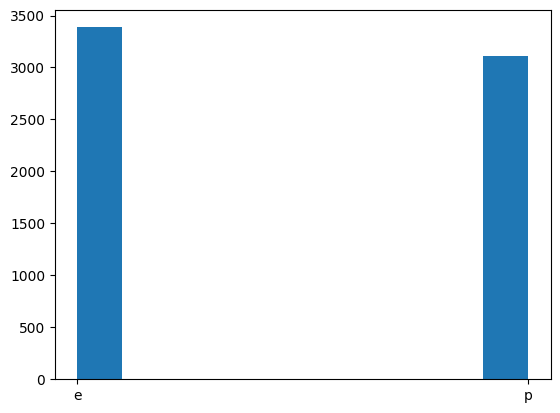

In [15]:
import matplotlib.pyplot as plt
plt.hist(train_data['class'])

<h2 align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
پیش‌پردازش و مهندسی ویژگی
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
    در این سوال شما می‌توانید از هر تکنیک پیش‌پردازش/مهندسی ویژگی که در فصل‌های گذشته آموختید، استفاده کنید.
    <br>
    تکنیک‌هایی که استفاده می‌کنید به شکل مستقیم مورد ارزیابی توسط سامانه داوری قرار <b>نمی‌گیرند.</b> بلکه همه آن‌ها در دقت مدل شما تاثیر خواهند گذاشت؛ بنابراین هر چه پیش‌پردازش/مهندسی ویژگی بهتری انجام دهید تا دقت مدل بهبود پیدا کند، امتیاز بیشتری از این سوال کسب خواهید کرد.
</font>
</p>

In [16]:
#replace columns that contain '?' to np.nan
mask = train_data.isin(['?']).sum(axis=0) > 0

for col in mask[mask].index:
  train_data[col] = train_data[col].replace({'?': np.nan})

train_data.isin(['?']).sum(axis=0)

class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64

In [17]:
#replace columns that contain '?' to np.nan
mask = test_data.isin(['?']).sum(axis=0) > 0

for col in mask[mask].index:
  test_data[col] = test_data[col].replace({'?': np.nan})

test_data.isin(['?']).sum(axis=0)

cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64

In [18]:
#replace columns that contain np.nan to mode of that column
mask = train_data.isnull().sum()  > 0
for col in mask[mask].index:
  train_data[col] = train_data[col].fillna(train_data[col].mode()[0])
train_data.isnull().sum()

class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64

In [19]:
#replace columns that contain np.nan to mode of that column
mask = test_data.isnull().sum()  > 0
for col in mask[mask].index:
  test_data[col] = test_data[col].fillna(test_data[col].mode()[0])
test_data.isnull().sum()

cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64

In [20]:
from sklearn.model_selection import train_test_split

#X = train_data.drop(columns=['class'])
X = train_data.drop('class', axis=1)
y = train_data['class']

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.33, random_state=42)

In [21]:
#label encoding for train & test dataset
from sklearn.preprocessing import LabelEncoder

for col in train_data.columns.drop(['class']):

  le = LabelEncoder()
  X_train[col] = le.fit_transform(X_train[col])
  X_val[col] = le.transform(X_val[col])
  test_data[col] = le.transform(test_data[col])


In [22]:
#label encoding for target column of train dataset: ['class]
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_val = le.fit_transform(y_val)


In [23]:
y_train = pd.DataFrame(y_train, columns = ['class'])

#reset_df = df.reset_index()
X_train = X_train.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)

#result = pd.concat([df1, df4], axis=1)
train_data = pd.concat([X_train, y_train], axis=1)

train_data

,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat,class
0,2,2,4,0,8,1,0,1,0,1,...,6,7,0,2,1,0,7,4,0,1
1,5,0,3,0,1,1,0,1,9,0,...,7,7,0,2,1,4,3,4,0,1
2,5,3,4,1,5,1,0,0,9,1,...,6,7,0,2,1,4,2,5,0,0
3,5,0,9,0,2,1,0,0,3,0,...,6,6,0,2,1,2,1,4,4,1
4,5,2,2,0,2,1,0,1,0,1,...,7,6,0,2,1,0,7,4,4,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4349,2,3,4,1,6,1,0,1,7,0,...,7,7,0,2,1,4,2,4,5,1
4350,5,3,3,1,5,1,0,0,7,1,...,3,7,0,2,1,4,2,4,0,0
4351,5,2,0,1,2,1,0,0,3,1,...,7,7,0,2,1,4,1,3,5,1
4352,5,3,9,0,2,1,0,0,7,0,...,4,0,0,2,1,2,1,4,0,1


In [24]:
y_val = pd.DataFrame(y_val, columns = ['class'])

X_val = X_val.reset_index(drop=True)
y_val = y_val.reset_index(drop=True)

val_data = pd.concat([X_val, y_val], axis=1)
val_data

,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat,class
0,2,0,4,0,5,1,1,0,3,1,...,7,7,0,2,1,0,2,0,1,0
1,5,2,4,0,2,1,0,1,0,1,...,6,6,0,2,1,0,7,4,4,1
2,2,3,9,0,2,1,0,0,2,0,...,4,6,0,2,1,2,1,4,4,1
3,2,2,2,0,8,1,0,1,0,1,...,7,7,0,2,1,0,7,4,2,1
4,5,0,3,0,2,1,0,0,3,0,...,6,6,0,2,1,2,1,4,4,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2140,5,0,2,1,5,1,0,0,9,1,...,6,6,0,2,1,4,3,5,0,0
2141,5,2,4,0,2,1,0,1,0,1,...,7,6,0,2,1,0,7,4,0,1
2142,5,2,2,0,2,1,0,1,0,1,...,7,6,0,2,1,0,7,4,0,1
2143,5,2,2,0,7,1,0,1,0,1,...,7,7,0,2,1,0,7,4,2,1


In [25]:
test_data

,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,5,0,4,1,5,1,0,0,7,1,...,2,3,6,0,2,1,4,2,5,0
1,5,0,8,0,5,1,1,0,5,1,...,0,7,7,0,2,1,0,2,0,1
2,5,0,3,0,5,1,1,0,5,1,...,2,7,7,0,2,1,0,2,0,1
3,2,0,3,1,5,1,0,0,9,1,...,2,3,7,0,2,1,4,3,5,0
4,5,3,2,1,5,1,0,0,5,1,...,2,6,6,0,2,1,4,3,4,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1620,3,3,4,0,2,1,0,1,0,1,...,1,7,6,0,2,1,0,7,4,0
1621,2,3,4,0,8,1,0,1,0,1,...,2,6,7,0,2,1,0,7,4,4
1622,5,3,3,0,2,1,0,0,7,0,...,1,0,4,0,2,1,2,1,4,4
1623,5,2,8,1,2,1,0,0,7,1,...,2,7,7,0,2,1,4,1,3,5


<h2 align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
مدل‌سازی
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
    حال که داده را پاکسازی کرده و احتمالا ویژگی‌هایی را به آن افزوده یا از آن حذف کرده‌اید، وقت آن است که مدلی آموزش دهید که بتواند متغیر هدف این مسئله را پیش‌بینی کند.
</font>
</p>

<h3 align=right style="direction: rtl;text-align: right;line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
    استفاده از <code>scikit-learn</code>
</font>
</h3>


<p dir=rtl style="direction: rtl;text-align: right;line-height:200%;font-family:vazir;font-size:medium">
<font face="vazir" size=3>
    الگوریتم <i>جنگل تصادفی</i> با نام <code>RandomForestClassifier</code> در پکیج <code>ensemble</code> این کتابخانه در دسترس است. برخی از آرگومان‌های مهم آن در جدول زیر آمده است، اما جهت مطالعه‌ی کامل‌تر مستندات می‌توانید به <a href="https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html" target="_blank">این لینک</a> مراجعه فرمایید.
</font>
</p>

<center>
<div dir=rtl style="line-height:200%;font-family:vazir;font-size:medium">
<font face="vazir" size=3>
    
|آرگومان|توضیحات|
|:------:|:---:|
|<code>n_estimators</code>|تعداد درخت جنگل|
|<code>max_depth</code>|حداکثر عمق یک درخت|
|<code>bootstrap</code>|آیا از تکنیک بوت‌استرپ در هنگام ساخت درخت استفاده شود یا خیر. اگر معادل <code>False</code> تنظیم شود از کل مجموعه‌داده استفاده خواهد شد.|
|<code>oob_score</code>|آیا از نمونه‌های خارج از بگ جهت ارزیابی استفاده شود یا خیر. تنها در صورتی که <code>bootstrap</code> معادل <code>True</code> تنظیم شده باشد.|
|<code>max_samples</code>|تعداد نمونه‌هایی که در بوت‌استرپ از مجموعه‌داده انتخاب می‌شود تا به کمک آن یک درخت تولید گردد.|
    
</font>
</div>
</center>


<h3 align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
آموزش مدل
</font>
</h3>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
    در سلول زیر با استفاده از مدل آماده‌ای که در بالا شرح داده شد و به کمک تابع <code>fit</code> الگوریتم را بر روی مجموعه‌ی آموزشی اجرا کنید.
</font>
</p>

In [26]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=100, random_state=42)

#model.fit(X_train, y_train)
model.fit(X_train, y_train.values.ravel())

y_pred = model.predict(X_val)

y_pred

array([0, 1, 1, ..., 1, 1, 0])

<h3 align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
معیار ارزیابی
</font>
</h3>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%;font-family:vazir;font-size:medium">
<font face="vazir" size=3>
    از آنجا که تشخیص اشتباه یک قارچ سمی به عنوان خوراکی می‌تواند منجر به مرگ شخصی شود، باید سعی کنیم به مدلی دست یابیم که تا حد ممکن قارچی را که سمی است به اشتباه خوراکی تشخیص ندهد. به بیان دیگر <code>tn</code> در این مسئله اهمیت بالایی دارد. به همین دلیل معیاری که برای ارزیابی عملکرد مدل انتخاب کرده‌ایم، معیار <code>Recall</code> است.
    <br>
    این معیار، سنجه ارزیابی کیفیت مدل شماست. به عبارت بهتر در سامانه داوری هم از همین معیار برای نمره‌دهی استفاده شده است.
    <br>
    پیشنهاد می‌شود با توجه به این معیار، عملکرد مدل خود را بر روی مجموعه‌ی آموزش یا اعتبارسنجی ارزیابی کنید.
    <br>
    برای محاسبه‌ی عملکرد مدل طبق این معیار می‌توانید از <code>sklearn.metrics.recall_score</code> استفاده کرده و از آنجا که قصد داریم دسته‌ی سمی را برابر کلاس مثبت در نظر بگیریم نیاز است تا آرگومان <code>pos_label</code> را معادل برچسب مربوط به کلاس سمی تنظیم کنید. جهت مطالعه‌ی مستندات این کلاس می‌توانید به <a href="https://scikit-learn.org/stable/modules/generated/sklearn.metrics.recall_score.html" target="_blank">این لینک</a> مراجعه فرمایید.
</font>
</p>

$$Recall=\frac{tp}{tp+fn}$$

In [27]:
# evaluate your model
from sklearn.metrics import recall_score

# To-Do
rs = recall_score(y_val, y_pred, pos_label=1, average='macro')
rs * 100

100.0

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font color="red"><b color='red'>توجه:</b></font>
<font face="vazir" size=3>
 جهت کسب امتیاز کامل نیاز است تا پاسخ شما امتیاز <code>100</code> را با توجه به معیار معرفی‌شده کسب نماید.
</font>
</p>

<h2 align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
 پیش‌بینی برای داده تست و خروجی
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
    پس از مهندسی ویژگی و مدل‌سازی، الگوریتمی دارید که می‌تواند شما را از متغیرهای مستقل به متغیر هدف برساند.
    <br>
    از این مدل برای پیش‌بینی نمونه‌های موجود در داده تست استفاده کنید و نتایج را در قالب جدول زیر آماده کنید.
</font>
</p>

<center>
<div dir=rtl style="line-height:200%;font-family:vazir;font-size:medium">
<font face="vazir" size=3>
    
|ستون|توضیحات|
|:------:|:---:|
|<code>class</code>|برچسب پیش‌بینی‌شده (سمی یا خوراکی)|
    
</font>
</div>
</center>


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
    توجه داده باشید که نوع قارچ را باید همچون مجموعه‌داده‌ی اولیه یعنی بصورت کاراکتر (<code>p</code> یا <code>e</code>) درج کنید.
</font>
</p>

In [28]:
# predict test samples

from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=100, random_state=42)

#model.fit(X_train, y_train)
model.fit(X_train, y_train.values.ravel())

y_pred = model.predict(test_data)

prediction = pd.DataFrame(y_pred, columns = ['class'])

#df['SrcAddr'] = df['SrcAddr'].replace(['10.0.2.15','10.0.2.2'],[0,0,0])
prediction = prediction.replace([1, 0], ['p','e'])

prediction

,class
0,e
1,e
2,e
3,e
4,e
...,...
1620,p
1621,p
1622,p
1623,p


<h2 align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
<b>سلول جواب‌ساز</b>
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
    برای ساخته‌شدن فایل <code>result.zip</code> سلول زیر را اجرا کنید. توجه داشته باشید که پیش از اجرای سلول زیر تغییرات اعمال شده در نت‌بوک را ذخیره کرده باشید (<code>ctrl+s</code>) تا در صورت نیاز به پشتیبانی امکان بررسی کد شما وجود داشته باشد.
</font>
</p>

In [29]:
import zipfile
import joblib

def compress(file_names):
    print("File Paths:")
    print(file_names)
    compression = zipfile.ZIP_DEFLATED
    with zipfile.ZipFile("result.zip", mode="w") as zf:
        for file_name in file_names:
            zf.write('./' + file_name, file_name, compress_type=compression)

joblib.dump(model, 'model')
prediction.to_csv('submission.csv', index=False)
file_names = ['mushroom_hunter.ipynb', 'submission.csv', 'model']
compress(file_names)

File Paths:
['mushroom_hunter.ipynb', 'submission.csv', 'model']
